# Paper plots

In this notebook we build plots for the paper

## Basic imports

In [1]:
%matplotlib notebook
import numpy as np
import pandas as pd

import os

import pickle

from matplotlib import pyplot as plt

import openfermion

from openfermion.hamiltonians import MolecularData
from openfermionpsi4 import run_psi4
from openfermion.transforms import get_fermion_operator, bravyi_kitaev, jordan_wigner, symmetry_conserving_bravyi_kitaev
from openfermion.utils import geometry_from_pubchem

DATA = '../../data/quantum_chemistry'
FIGS = '../../figures'

# Plotting the results

In [2]:
mol_names = ['H2_reduced', 'LiH_psi4_reduced']

In [3]:
r_methods = ['simcim_cpp_k_local']
non_r_methods = ['FCI', 'HF']

In [4]:
mol_name_to_r_nums_dict = {
    'LiH_psi4_reduced': [2],
    'H2_reduced': [2, 3, 16]
}

In [5]:
x_axes = {}
for mol_name in mol_names:
    with open(f'{DATA}/{mol_name}_x.pickle', 'rb') as handle:
        x_axes[mol_name] = pickle.load(handle)
        
y_axes = {}
for mol_name in mol_names:
    with open(f'{DATA}/{mol_name}_y.pickle', 'rb') as handle:
        y_axes[mol_name] = pickle.load(handle)

In [6]:
updated_x_axes = x_axes

In [7]:
updated_y_axes = y_axes

In [8]:
method_to_label = {
    'brute_force': 'Brute force',
    'simcim_cpp': 'SimCIM',
    'simcim_cpp_k_local': 'PolySimCIM',
    'exact': 'Exact',
    'FCI': 'FCI',
    'HF': 'Hartree-Fock'
}
method_to_color = {
    'brute_force': 'xkcd:yellowish orange',
    'simcim_cpp':  'xkcd:light red',
    'simcim_cpp_k_local': 'xkcd:bright blue',
    'exact': 'black',
    'FCI': 'black',
    'HF': 'xkcd:light red',
}
method_to_ms = {
    'simcim_cpp': 7,
    'simcim_cpp_k_local': 10,
    'brute_force': 4,
    'exact': 4,
    'FCI': 1,
    'HF': 1,
}
method_to_linewidth = {
    'brute_force': 2,
    'simcim_cpp': 3.5,
    'simcim_cpp_k_local': 3,
    'exact': 1,
    'FCI': 1,
    'HF': 1,
}
r_num_to_linestyle = {
    16: '-',
    3: '-',
    2: '-',
}
r_num_to_marker = {
    16: 'o',
    3: '*',
    2: 's',
}
method_to_alpha = {
    'brute_force': 1,
    'simcim_cpp': 0.6,
    'simcim_cpp_k_local': 0.8,
}
mol_name_to_title = {
    'H2_reduced': f'$H_2,\\ M=2$',
    'helium_2': f'$He_2$',
    'LiH_psi4_reduced': f'$LiH,\\ M=10$',
}
mol_name_to_xlim = {
    'H2_reduced': (0.0, 6.0),
    'helium_2': (0.5, 4.5),
    'LiH_psi4_reduced': (0.5, 5.0),
}
mol_name_to_ylim = {
    'H2_reduced': (-1.2, 0.4),
    'helium_2': (-6.0, 0.0),
    'LiH_psi4_reduced': (-8.0, -5.0),
}
mol_name_to_fig_name = {
    'H2_reduced': 'hydrogen',
    'LiH_psi4_reduced': 'lithium_hydride'
}
r_num_to_color = {
    2: 'xkcd:yellowish orange',
    3:  'xkcd:green',
    16: 'xkcd:periwinkle',
}
figsize = 10
linewidth = 3
angstrom_to_au = 1.0 / 0.52
fs = 20
fontweight=None

In [9]:
import matplotlib
font = {'family' : 'normal',
        'weight' : 'bold',
        'size'   : fs}

matplotlib.rc('font', **font)

## Main plot

<IPython.core.display.Javascript object>


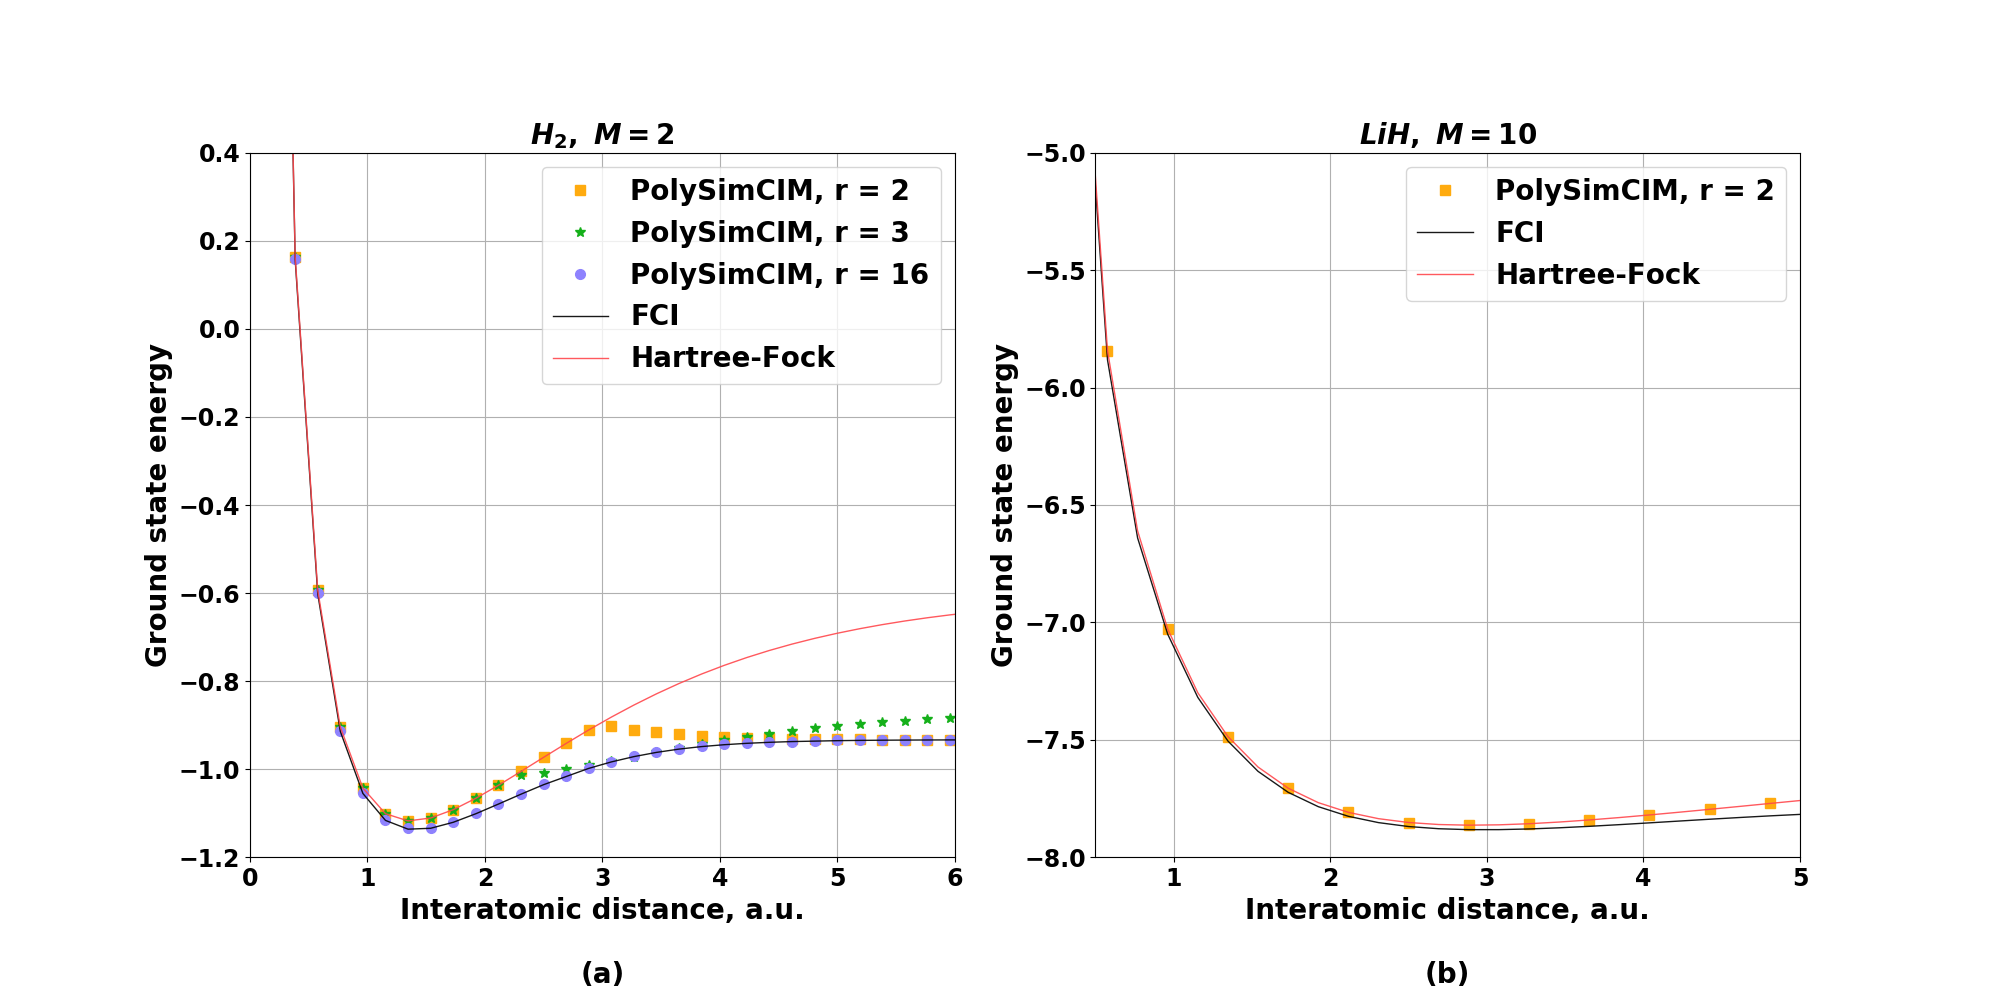

findfont: Font family ['normal'] not found. Falling back to DejaVu Sans.
findfont: Font family ['normal'] not found. Falling back to DejaVu Sans.


In [10]:
fig, ax = plt.subplots(1, 2)
fig.set_figwidth(2 * figsize)
fig.set_figheight(figsize)

for idx, mol_name in enumerate(mol_names):
    for method in r_methods:
        for r_num in mol_name_to_r_nums_dict[mol_name]:
                ax[idx].plot(updated_x_axes[mol_name][method][r_num] * angstrom_to_au,
                        updated_y_axes[mol_name][method][r_num],
                        label=method_to_label[method] + f', r = {r_num}',
                        linewidth=method_to_linewidth[method],
                        linestyle='',
                        marker=r_num_to_marker[r_num],
                        ms=7,
                        color=r_num_to_color[r_num],
                       )

    for method in non_r_methods:
        ax[idx].plot(x_axes[mol_name][method] * angstrom_to_au,
                y_axes[mol_name][method],
                label=method_to_label[method],
                linewidth=method_to_linewidth[method],
                linestyle='-',
                #linestyle='',
                #marker='o',
                #ms=method_to_ms['exact'],
                color=method_to_color[method],
                alpha=0.9)

    ax[idx].set_title(mol_name_to_title[mol_name], fontsize=fs, fontweight=fontweight)
    ax[idx].legend(loc='best', fontsize=fs)
    ax[idx].set_xlabel('Interatomic distance, a.u.\n\n' + ('(a)' if idx == 0 else '(b)'), fontsize=fs, fontweight=fontweight)
    for tick in ax[idx].xaxis.get_major_ticks():
        tick.label.set_fontsize(fs-3) 
        tick.label.set_fontweight(fontweight) 
    ax[idx].set_ylabel('Ground state energy', fontsize=fs, fontweight=fontweight)
    for tick in ax[idx].yaxis.get_major_ticks():
        tick.label.set_fontsize(fs-3) 
        tick.label.set_fontweight(fontweight) 

    ax[idx].set_xlim(mol_name_to_xlim[mol_name])
    ax[idx].set_ylim(mol_name_to_ylim[mol_name])
    asp = np.diff(ax[idx].get_xlim())[0] / np.diff(ax[idx].get_ylim())[0]
    ax[idx].set_aspect(asp)
    #ax[idx].set_aspect(aspect='equal', adjustable='datalim')
    ax[idx].grid()
fig.savefig(f'{FIGS}/quantum_chemistry.pdf', format='pdf', dpi=300)

## Distance to the ground state

In [11]:
chem_acc_x_axes = {}
for mol_name in mol_names:
    with open(f'{DATA}/{mol_name}_chem_acc_x.pickle', 'rb') as handle:
        chem_acc_x_axes[mol_name] = pickle.load(handle)
        
chem_acc_y_axes = {}
for mol_name in mol_names:
    with open(f'{DATA}/{mol_name}_chem_acc_y.pickle', 'rb') as handle:
        chem_acc_y_axes[mol_name] = pickle.load(handle)

<IPython.core.display.Javascript object>


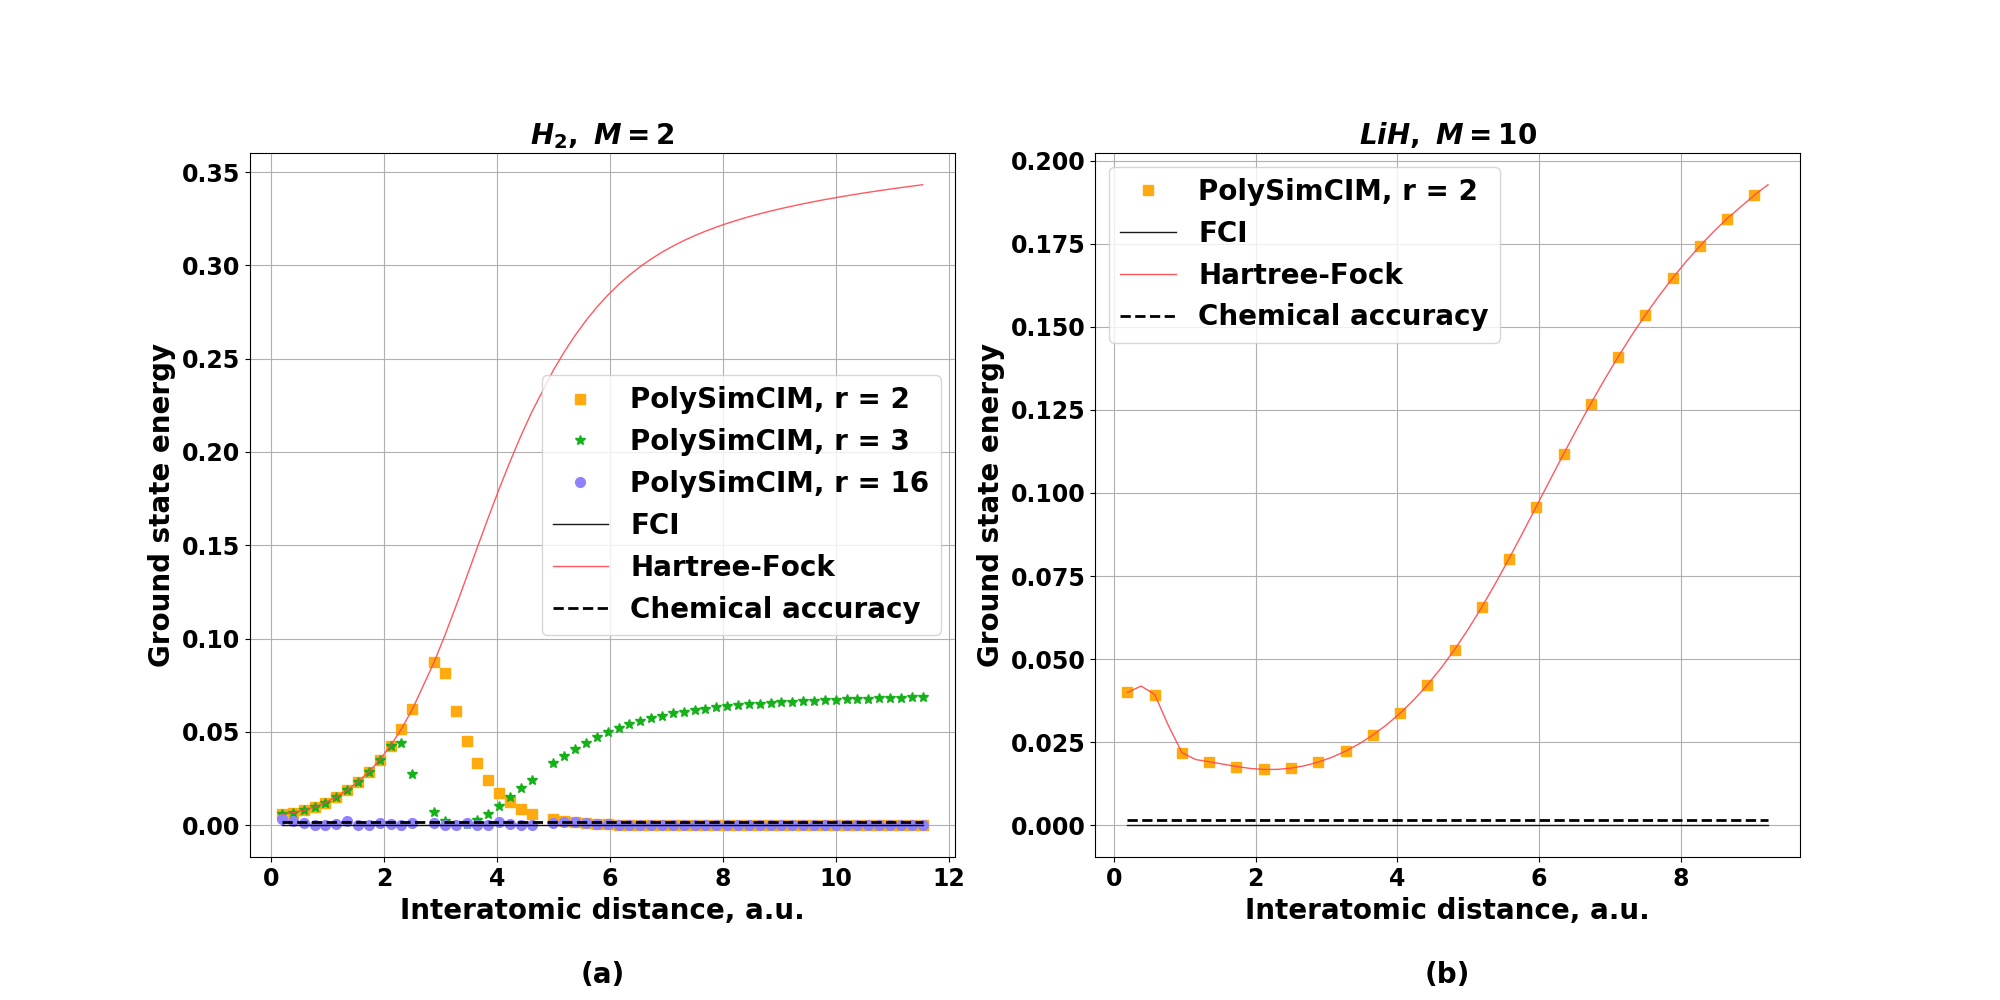

In [12]:
fig, ax = plt.subplots(1, 2)
fig.set_figwidth(2 * figsize)
fig.set_figheight(figsize)

for idx, mol_name in enumerate(mol_names):
    for method in r_methods:
        for r_num in mol_name_to_r_nums_dict[mol_name]:
                ax[idx].plot(chem_acc_x_axes[mol_name][method][r_num] * angstrom_to_au,
                        chem_acc_y_axes[mol_name][method][r_num],
                        label=method_to_label[method] + f', r = {r_num}',
                        linewidth=method_to_linewidth[method],
                        linestyle='',
                        marker=r_num_to_marker[r_num],
                        ms=7,
                        color=r_num_to_color[r_num],
                        #alpha=r_num_to_alpha[r_num]
                       )

    for method in non_r_methods:
        ax[idx].plot(chem_acc_x_axes[mol_name][method] * angstrom_to_au,
                chem_acc_y_axes[mol_name][method],
                label=method_to_label[method],
                linewidth=method_to_linewidth[method],
                linestyle='-',
                #linestyle='',
                #marker='o',
                #ms=method_to_ms['exact'],
                color=method_to_color[method],
                alpha=0.9)
    ax[idx].plot(chem_acc_x_axes[mol_name]['FCI'] * angstrom_to_au,
        chem_acc_y_axes[mol_name]['FCI'] + 1.6e-3,
        label='Chemical accuracy',
        linewidth=2,
        linestyle='--',
        #linestyle='',
        #marker='o',
        #ms=method_to_ms['exact'],
        color='k',
        alpha=1.0)

    ax[idx].set_title(mol_name_to_title[mol_name], fontsize=fs, fontweight=fontweight)
    ax[idx].legend(loc='best', fontsize=fs)
    ax[idx].set_xlabel('Interatomic distance, a.u.\n\n' + ('(a)' if idx == 0 else '(b)'), fontsize=fs, fontweight=fontweight)
    for tick in ax[idx].xaxis.get_major_ticks():
        tick.label.set_fontsize(fs-3) 
        tick.label.set_fontweight(fontweight) 
    ax[idx].set_ylabel('Ground state energy', fontsize=fs, fontweight=fontweight)
    for tick in ax[idx].yaxis.get_major_ticks():
        tick.label.set_fontsize(fs-3) 
        tick.label.set_fontweight(fontweight) 

    #ax[idx].set_xlim(mol_name_to_xlim[mol_name])
    #ax[idx].set_ylim(mol_name_to_ylim[mol_name])
    asp = np.diff(ax[idx].get_xlim())[0] / np.diff(ax[idx].get_ylim())[0]
    ax[idx].set_aspect(asp)
    #ax[idx].set_aspect(aspect='equal', adjustable='datalim')
    ax[idx].grid()
# fig.savefig(f'{FIGS}/quantum_chemistry.pdf', format='pdf', dpi=300)

## PUBO vs. QUBO comparison

In [13]:
molecules = ['LiH_equilibrium_reduced', 'H2_equilibrium', 'H2_equilibrium_reduced']

In [14]:
data = {}
for molecule in molecules:
    data[molecule] = pd.read_table(f'{DATA}/{molecule}.out')
data['LiH_equilibrium_reduced'] = data['LiH_equilibrium_reduced'].append(pd.DataFrame([[4, 40, 1570819, 17916, 6336895]], columns=data['LiH_equilibrium_reduced'].columns))
data['LiH_equilibrium_reduced'] = data['LiH_equilibrium_reduced'].append(pd.DataFrame([[5, 50, 2617606, 28155, 12378893]], columns=data['LiH_equilibrium_reduced'].columns))

In [16]:
molecule_to_label = {
    'H2_equilibrium_reduced': f'$H_{2},\\ M=2$',
#     'H2_equilibrium': f'$H_{2},\\ M=4$',
    'LiH_equilibrium_reduced': f'$LiH,\\ M=10$',
}

molecule_to_marker = {
    'H2_equilibrium_reduced': 'o',
    'H2_equilibrium': 's',
    'LiH_equilibrium_reduced': '*',
}

molecule_to_color = {
    'H2_equilibrium_reduced': 'xkcd:yellowish orange',
    'H2_equilibrium': 'xkcd:green',
    'LiH_equilibrium_reduced': 'xkcd:periwinkle',
}

<IPython.core.display.Javascript object>


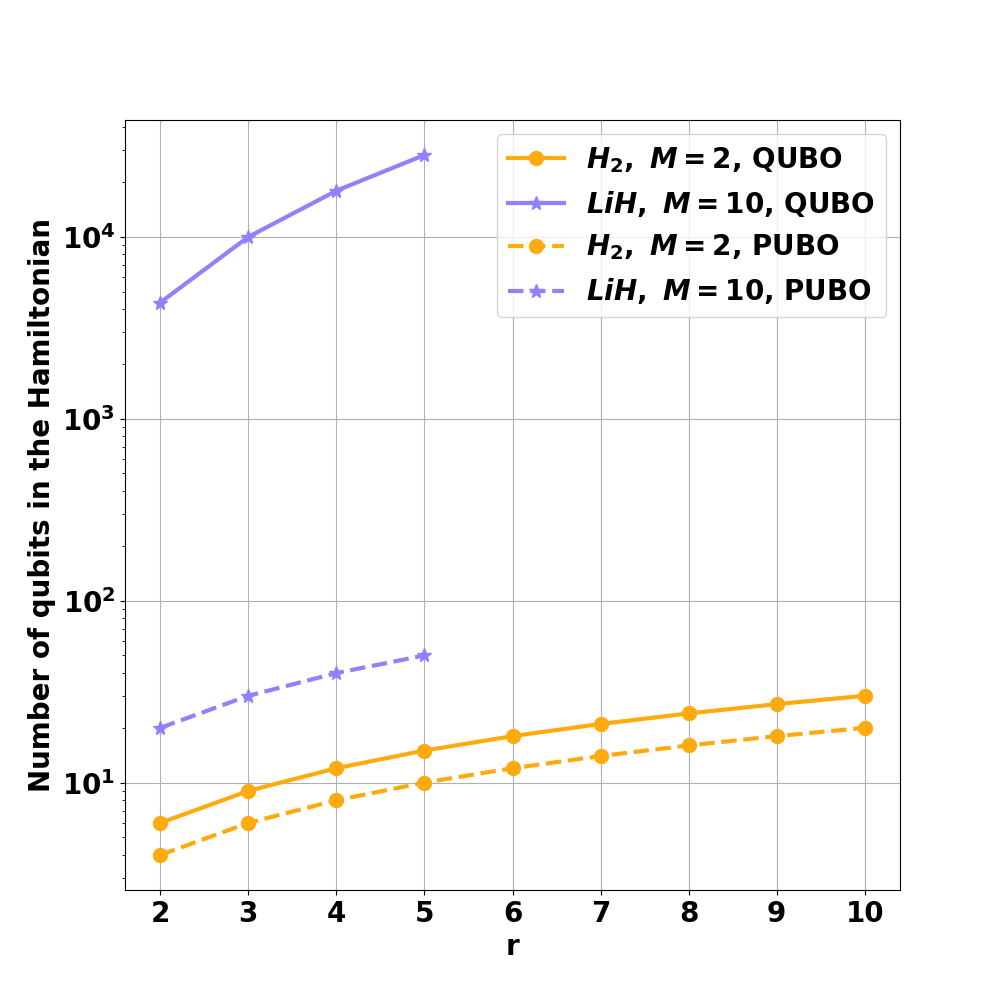

In [17]:
fig, ax_qubit = plt.subplots()
fig.set_figwidth(figsize)
fig.set_figheight(figsize)

ax_qubit.grid()
# ax_qubit.grid(which='minor', linewidth=0.35, color='k', alpha=0.5)
# ax_qubit.grid(which='major', linewidth=1, color='k', alpha=0.5)

for molecule in molecule_to_label:
    ax_qubit.plot(data[molecule]['r'],
                  data[molecule]['QUBO_qubit_num'],
                  label=f'{molecule_to_label[molecule]}, QUBO',
                  linewidth=3,
                  color=molecule_to_color[molecule],
                  marker=molecule_to_marker[molecule],
                  ms=10,)
    
for molecule in molecule_to_label:
    ax_qubit.plot(data[molecule]['r'],
                  data[molecule]['PUBO_qubit_num'],
                  label=f'{molecule_to_label[molecule]}, PUBO',
                  linestyle='--',
                  linewidth=3,
                  color=molecule_to_color[molecule],
                  marker=molecule_to_marker[molecule],
                  ms=10,)

ax_qubit.legend(loc='best')

ax_qubit.set_xlabel(f'r', fontsize=fs, fontweight=fontweight)
ax_qubit.set_ylabel(f'Number of qubits in the Hamiltonian', fontsize=fs, fontweight=fontweight)
ax_qubit.set_yscale('log')

fig.savefig(f'{FIGS}/qubit_scaling.pdf', format='pdf', dpi=300)

# ax_term = ax_qubit.twinx()
# for molecule in molecule_to_label:
#     ax_term.plot(data[molecule]['r'],
#                  data[molecule]['QUBO_term_num'],
#                  label=f'{molecule_to_label[molecule]}',
#                  linewidth=3,
#                  linestyle='--',
#                  color=molecule_to_color[molecule],
#                  marker=molecule_to_marker[molecule],
#                  ms=10,)
    
# ax_term.legend(loc='best')

# ax_term.set_xlabel(f'r', fontsize=fs, fontweight=fontweight)
# ax_term.set_ylabel(f'Number of terms in the QUBO Hamiltonian', fontsize=fs, fontweight=fontweight)
# ax_term.set_yscale('log')

<IPython.core.display.Javascript object>


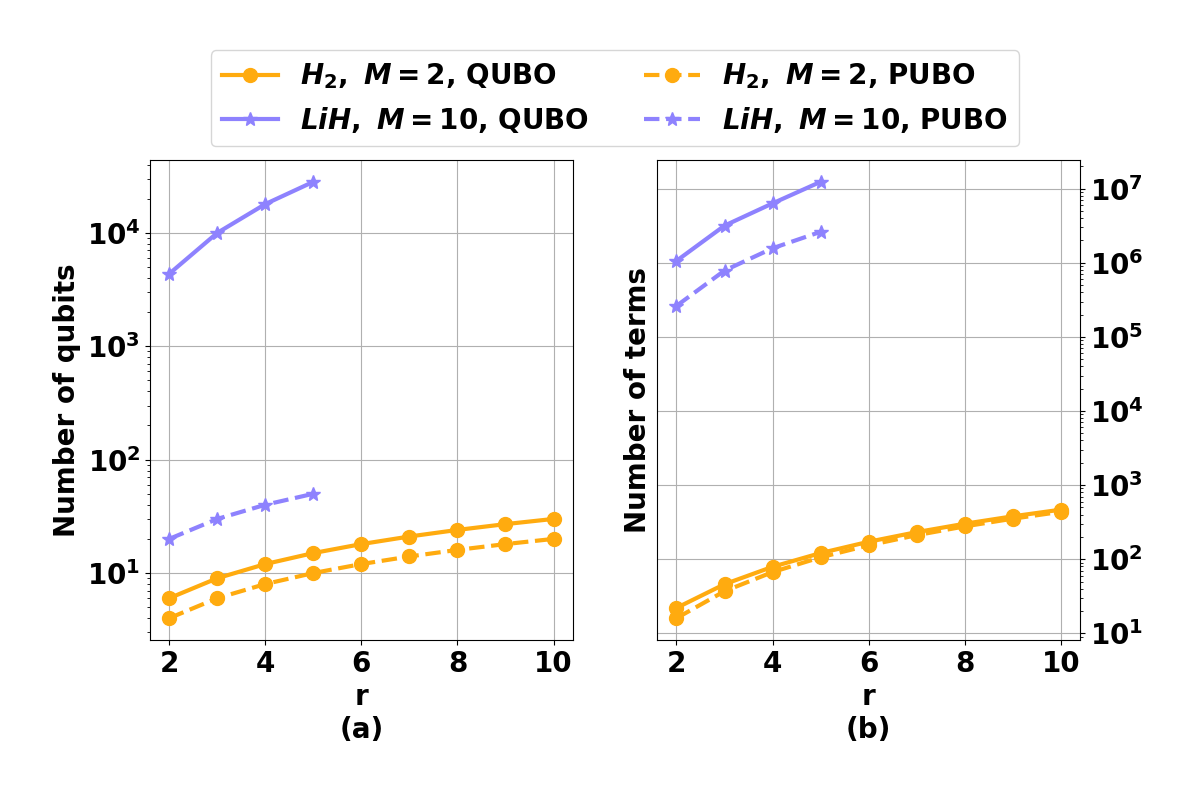

In [74]:
fig, axes = plt.subplots(1, 2)
fig.set_figwidth(12)
fig.set_figheight(8)
fig.subplots_adjust(top=0.8, bottom=0.2)

ax_qubit = axes[0]
ax_qubit.grid()
# ax_qubit.grid(which='minor', linewidth=0.35, color='k', alpha=0.5)
# ax_qubit.grid(which='major', linewidth=1, color='k', alpha=0.5)

for molecule in molecule_to_label:
    ax_qubit.plot(data[molecule]['r'],
                  data[molecule]['QUBO_qubit_num'],
                  label=f'{molecule_to_label[molecule]}, QUBO',
                  linewidth=3,
                  color=molecule_to_color[molecule],
                  marker=molecule_to_marker[molecule],
                  ms=10,)
    
for molecule in molecule_to_label:
    ax_qubit.plot(data[molecule]['r'],
                  data[molecule]['PUBO_qubit_num'],
                  label=f'{molecule_to_label[molecule]}, PUBO',
                  linestyle='--',
                  linewidth=3,
                  color=molecule_to_color[molecule],
                  marker=molecule_to_marker[molecule],
                  ms=10,)

ax_qubit.legend(loc='lower center', bbox_to_anchor=(1.1, 1.0), ncol=2)

ax_qubit.set_xlabel(f'r\n(a)', fontsize=fs, fontweight=fontweight)
ax_qubit.set_ylabel(f'Number of qubits', fontsize=fs, fontweight=fontweight)
ax_qubit.set_yscale('log')

ax_term = axes[1]
ax_term.grid()
for molecule in molecule_to_label:
    ax_term.plot(data[molecule]['r'],
                 data[molecule]['QUBO_term_num'],
                 label=f'{molecule_to_label[molecule]}, QUBO',
                 linewidth=3,
                 linestyle='-',
                 color=molecule_to_color[molecule],
                 marker=molecule_to_marker[molecule],
                 ms=10,)
    ax_term.plot(data[molecule]['r'],
                 data[molecule]['PUBO_term_num'],
                 label=f'{molecule_to_label[molecule]}, PUBO',
                 linewidth=3,
                 linestyle='--',
                 color=molecule_to_color[molecule],
                 marker=molecule_to_marker[molecule],
                 ms=10,)
    
# ax_term.legend(loc='best')

ax_term.set_xlabel(f'r\n(b)', fontsize=fs, fontweight=fontweight)
ax_term.set_ylabel(f'Number of terms', fontsize=fs, fontweight=fontweight)
ax_term.set_yscale('log')
ax_term.yaxis.tick_right()
fig.savefig(f'{FIGS}/qubit_and_term_scaling.pdf', format='pdf', dpi=300)